# 05 — Time-series foundation models, zero-shot

A foundation model for time series is a large network pretrained on millions of real and
synthetic series; it forecasts a new series **without being trained on it** (zero-shot), from
its context alone, and returns quantiles. It is the way to bring "what spending series usually
look like" to a single household without collecting anyone's data, the knowledge the pooled
LightGBM of notebook 04 got from 60 households.

Four local, open-weight models (weights downloaded once to the Hugging Face cache, nothing
sent anywhere; **TimeGPT is excluded**: it is a cloud API, and the spending must never leave the
host, spec §6):

| Model | Size | Notes |
|---|---|---|
| Chronos-Bolt small (Amazon) | 48 M | T5 encoder–decoder on patches, direct multi-step quantiles |
| Chronos-Bolt base | 205 M | the same, larger |
| Chronos-2 (Amazon) | 120 M | 2025 successor, group attention, covariates (unused here) |
| TimesFM 2.5 (Google) | 200 M | decoder-only, continuous quantile head |

Same protocol: the 658 variable series, 7 origins, 12 months ahead, the context being the
months up to each origin (24 to 36), never later.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import torch

import study

warnings.filterwarnings("ignore")
v = study.bench()
cuts = study.cutoffs(v, n_windows=7, step=2)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")
series = {uid: g.sort_values("ds") for uid, g in v.groupby("unique_id")}
ids = list(series)

def contexts(c):
    return [torch.tensor(series[u].loc[series[u]["ds"] <= c, "y"].to_numpy(), dtype=torch.float32) for u in ids]

def frame(c, name, q10, q50, q90, mean=None):
    ds = pd.date_range(c + pd.DateOffset(months=1), periods=12, freq="MS")
    out = []
    for i, u in enumerate(ids):
        out.append(pd.DataFrame({"unique_id": u, "ds": ds, "cutoff": c, name: (mean if mean is not None else q50)[i],
                                 f"{name}-q10": q10[i], f"{name}-q50": q50[i], f"{name}-q90": q90[i]}))
    return pd.concat(out)

timings = {}

def run_chronos(model_id: str, name: str) -> pd.DataFrame:
    from chronos import BaseChronosPipeline
    pipe = BaseChronosPipeline.from_pretrained(model_id, device_map=device, torch_dtype=torch.float32)
    parts, t = [], time.perf_counter()
    for c in cuts:
        q, mean = pipe.predict_quantiles(contexts(c), prediction_length=12, quantile_levels=[0.1, 0.5, 0.9])
        q = torch.cat(q) if isinstance(q, list) else q
        q = q.cpu().numpy()
        parts.append(frame(c, name, q[..., 0], q[..., 1], q[..., 2]))
    timings[name] = time.perf_counter() - t
    return pd.concat(parts)

def run_timesfm() -> pd.DataFrame:
    import timesfm
    m = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
    m.compile(timesfm.ForecastConfig(max_context=64, max_horizon=16, normalize_inputs=True,
                                     use_continuous_quantile_head=True, fix_quantile_crossing=True))
    parts, t = [], time.perf_counter()
    for c in cuts:
        point, q = m.forecast(horizon=12, inputs=[x.numpy() for x in contexts(c)])
        # q[..., 0] is the mean, then the deciles 0.1 … 0.9
        parts.append(frame(c, "TimesFM 2.5", q[..., 1], q[..., 5], q[..., 9], mean=point))
    timings["TimesFM 2.5"] = time.perf_counter() - t
    return pd.concat(parts)

def compute() -> pd.DataFrame:
    keys = ["unique_id", "ds", "cutoff"]
    out = run_chronos("amazon/chronos-bolt-small", "Chronos-Bolt small")
    for model_id, name in [("amazon/chronos-bolt-base", "Chronos-Bolt base"), ("amazon/chronos-2", "Chronos-2")]:
        out = out.merge(run_chronos(model_id, name), on=keys)
    out = out.merge(run_timesfm(), on=keys)
    print({k: f"{t:.1f} s for {len(cuts) * len(ids)} forecasts" for k, t in timings.items()})
    return out

fm = study.cached("fm_bench", compute)
FM = ["Chronos-Bolt small", "Chronos-Bolt base", "Chronos-2", "TimesFM 2.5"]
fm[["unique_id", "ds", "cutoff", *FM]].head()

device: cuda NVIDIA GeForce RTX 5070 Laptop GPU


,unique_id,ds,cutoff,Chronos-Bolt small,Chronos-Bolt base,Chronos-2,TimesFM 2.5
0,002/Children,2024-01-01,2023-12-01,265.088745,270.169586,269.173187,266.137115
1,002/Children,2024-02-01,2023-12-01,268.441711,267.261749,325.742554,312.271027
2,002/Children,2024-03-01,2023-12-01,263.572083,263.104370,299.145111,300.922607
3,002/Children,2024-04-01,2023-12-01,260.487549,257.272522,274.487762,241.197449
4,002/Children,2024-05-01,2023-12-01,263.202728,255.038498,270.000641,265.827026


## Point accuracy, against the statistical and ML leaders

In [2]:
keys = ["unique_id", "ds", "cutoff"]
stats_cv = study.cached("stats_bench", lambda: None)
ml = study.cached("ml_mlforecast", lambda: None)
mlh = study.cached("ml_per_household", lambda: None)
allcv = (stats_cv[keys + ["y", "Mean6", "ETS", "ARIMA"]].merge(ml[keys + ["LGBM global"]], on=keys)
         .merge(mlh, on=keys).merge(fm, on=keys))
MODELS = ["Mean6", "ETS", "ARIMA", "LGBM global", "LGBM per household", *FM]
scores = study.point_scores(allcv, v, MODELS)
study.summary(scores, baseline="Mean6").round(3)

,MASE,MASE median,RMSSE,WAPE,bias,beats baseline
model,,,,,,
TimesFM 2.5,0.768,0.679,0.788,0.107,0.034,0.732
Chronos-2,0.783,0.693,0.812,0.108,0.039,0.692
LGBM global,0.819,0.707,0.778,0.125,0.007,0.656
ARIMA,0.838,0.747,0.814,0.118,0.006,0.581
Chronos-Bolt base,0.845,0.729,0.878,0.138,0.072,0.629
Chronos-Bolt small,0.849,0.731,0.880,0.140,0.074,0.629
ETS,0.850,0.735,0.807,0.112,0.007,0.582
LGBM per household,0.909,0.794,0.858,0.145,0.011,0.508
Mean6,0.944,0.832,0.893,0.174,0.007,0.000


In [3]:
ranks, p, cd = study.friedman_nemenyi(scores)
print(ranks.round(2).to_string())
print(f"Friedman p = {p:.2g}; Nemenyi CD = {cd:.3f}")

model
TimesFM 2.5           3.77
Chronos-2             4.13
LGBM global           4.73
ETS                   4.92
ARIMA                 4.98
Chronos-Bolt small    5.10
Chronos-Bolt base     5.14
Mean6                 6.05
LGBM per household    6.19
Friedman p = 0; Nemenyi CD = 0.177


In [4]:
scores["category"] = scores["unique_id"].str.split("/").str[1]
scores.dropna(subset=["mase"]).pivot_table(index="category", columns="model", values="mase")[
    ["Mean6", "ETS", "LGBM global", *FM]].round(2)

model,Mean6,ETS,LGBM global,Chronos-Bolt small,Chronos-Bolt base,Chronos-2,TimesFM 2.5
category,,,,,,,
Children,0.78,0.62,0.55,0.74,0.74,0.61,0.58
Gifts,1.23,1.30,1.17,1.00,1.00,0.98,1.00
Groceries,0.85,0.84,0.76,0.83,0.83,0.82,0.78
Health,0.98,0.96,0.94,0.92,0.92,0.92,0.92
Home,0.92,0.89,0.85,0.82,0.83,0.83,0.82
Housing,0.89,0.06,0.17,0.53,0.51,0.17,0.15
Leisure,1.02,0.92,0.68,0.81,0.81,0.73,0.68
Miscellaneous,0.82,0.80,0.77,0.77,0.77,0.77,0.77
Salaries,1.01,0.67,0.96,0.96,0.92,0.75,0.73


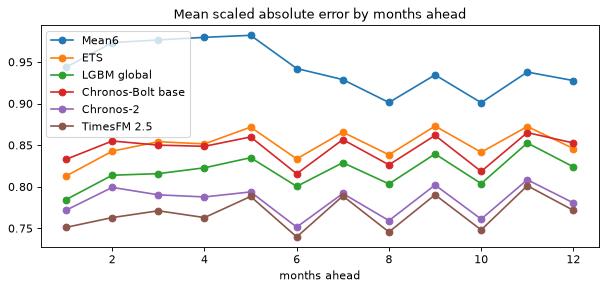

In [5]:
import matplotlib.pyplot as plt
study.by_horizon(allcv, v, ["Mean6", "ETS", "LGBM global", "Chronos-Bolt base", "Chronos-2", "TimesFM 2.5"]).plot(
    marker="o", title="Mean scaled absolute error by months ahead")
plt.xlabel("months ahead")
plt.show()

## Cost: what it would take to run in the app

The app's image carries numpy, statsforecast and LightGBM (a few hundred MB). A foundation
model adds PyTorch (about 2 GB for the CPU build, more with CUDA) and its weights, and must run
on the home server's CPU. One household's forecast is about 15 series × (23 back-test cuts + 1);
the timing below is that workload on the CPU, with Chronos-Bolt small, the lightest.

In [6]:
from chronos import BaseChronosPipeline

cpu = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu", torch_dtype=torch.float32)
one = [torch.tensor(series[u]["y"].to_numpy()[:36], dtype=torch.float32) for u in ids[:15]]
t = time.perf_counter()
for _ in range(24):
    cpu.predict_quantiles(one, prediction_length=12, quantile_levels=[0.1, 0.5, 0.9])
print(f"Chronos-Bolt small on CPU: {time.perf_counter() - t:.1f} s for one household's 24 runs")
cpu2 = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map="cpu")
t = time.perf_counter()
for _ in range(24):
    cpu2.predict_quantiles(one, prediction_length=12, quantile_levels=[0.1, 0.5, 0.9])
print(f"Chronos-2 on CPU: {time.perf_counter() - t:.1f} s for one household's 24 runs")
import importlib.metadata as md
print("torch", md.version("torch"), "| site-packages size of torch:",
      f"{sum(f.stat().st_size for f in __import__('pathlib').Path(torch.__file__).parent.rglob('*') if f.is_file()) / 1e9:.1f} GB")

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Chronos-Bolt small on CPU: 0.4 s for one household's 24 runs


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos-2 on CPU: 1.1 s for one household's 24 runs
torch 2.14.1 | site-packages size of torch: 1.2 GB


## What the foundation models show

- **Zero-shot, the two 2025 models are the most accurate of the whole study**: TimesFM 2.5
  (MASE 0.768, beating the 6-month mean on 73 % of the series-origins) and Chronos-2 (0.783,
  69 %), ahead of the pooled LightGBM (0.819), ARIMA (0.838) and ETS (0.850), and far ahead of
  what the app's per-household trees reach (0.909). They are the best ranked by the Friedman test,
  by more than the Nemenyi critical difference. Unlike the pooled LightGBM they need **no other
  household's data**: their "pooled knowledge" comes from pretraining.
- They win almost everywhere: children, gifts, home, leisure, savings, shopping. ETS keeps the
  property tax and stays close on salaries.
- The older Chronos-Bolt models are only on a par with ETS (0.845–0.849).
- **Their weakness is a bias**: +3 to +4 % of the money for TimesFM and Chronos-2 (+7 % for
  Chronos-Bolt), i.e. they **under-forecast** spending. Their pooled WAPE (10.7–10.8 %) is
  nonetheless as good as the best statistical models'. A bias towards less spending is the wrong
  direction for a budget; the app's conformal bands would absorb it (the errors are measured),
  but the point forecast would read optimistic.
- **Cost**: on this laptop's GPU, the Chronos models forecast the 4,606 series-origins in under
  2 s; on the **CPU**, one household's whole back-test (15 series × 24 runs) takes well under half a
  second for Chronos-Bolt small and about one second for Chronos-2 (timings vary a little
  between runs). Speed is not
  the obstacle. The obstacles are packaging (PyTorch and the weights in the image, the first
  download of the weights from the Hugging Face hub, which a self-hosted app must pin and
  verify) and trust (a 100-million-parameter model whose behaviour on a household's odd month
  is harder to explain than an average).

The spec (§4.14 F-FCT-3) keeps them out of the app's image and leaves their value to this
study: **on this synthetic panel they earn their place on accuracy**, by a clear margin. Notebook
09 weighs that against the packaging and the bias.